In [2]:
import sys, os, datetime, importlib

import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
import tqdm

import nn_reg; importlib.reload(nn_reg)
import nn_tf; importlib.reload(nn_tf)

<module 'nn_tf' from '/mnt/c/Users/user/Desktop/rnd/AISat/VolumeInversion/nn_tf.py'>

In [ ]:
importlib.reload(script_CoreExplorer)

#[plt.plot(script_CoreExplorer.WienerNoiser(torch.zeros(1,1,100), 2.0, 10)[0,0]) for _ in range(100)]; plt.show()
plt.plot(script_CoreExplorer.WienerNoiser(torch.zeros(1,1,100), 1.0, 10)[0,0])
plt.plot(script_CoreExplorer.WienerNoiser(torch.zeros(1,1,100), 2.0, 10)[0,0])
plt.plot(script_CoreExplorer.WienerNoiser(torch.zeros(1,1,100), 3.0, 10)[0,0])
plt.plot(script_CoreExplorer.WienerNoiser(torch.zeros(1,1,100), 4.0, 10)[0,0])
plt.title('Random process noise - vary magnitude'); plt.legend([f't={v}' for v in np.linspace(1,4,4)]); plt.show()
plt.plot(script_CoreExplorer.WienerNoiser(torch.zeros(1,1,100), 1.0, 10)[0,0])
plt.plot(script_CoreExplorer.WienerNoiser(torch.zeros(1,1,100), 1.0, 20)[0,0])
plt.plot(script_CoreExplorer.WienerNoiser(torch.zeros(1,1,100), 1.0, 30)[0,0])
plt.plot(script_CoreExplorer.WienerNoiser(torch.zeros(1,1,100), 1.0, 40)[0,0])
plt.title('Random process noise - vary spatial correlation'); plt.legend([f'L={v}' for v in np.linspace(10,40,4)]); plt.show()

In [6]:
import brack2bing
icesim = brack2bing.LatticeSolver.load()
#icesim.gen_lattice(

/mnt/c/Users/user/Desktop/rnd/AISat/VolumeInversion/script_CoreExplorer.py:193: UserWarning: requested count 5000 exceeds dataset sample count 103; retrieving 103 samples.
  if (count > w_ind): warnings.warn(f'requested count {count} exceeds dataset sample count {w_ind}; retrieving {w_ind} samples.')


[22.19 28.16 34.5  41.36 49.04 58.17]


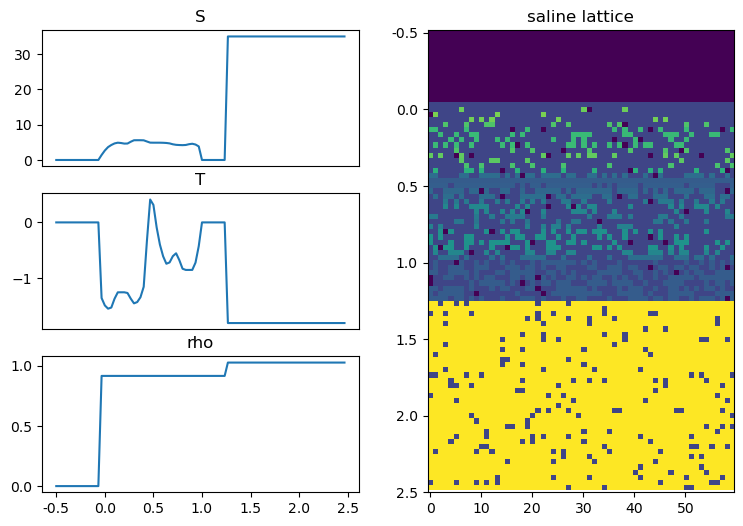

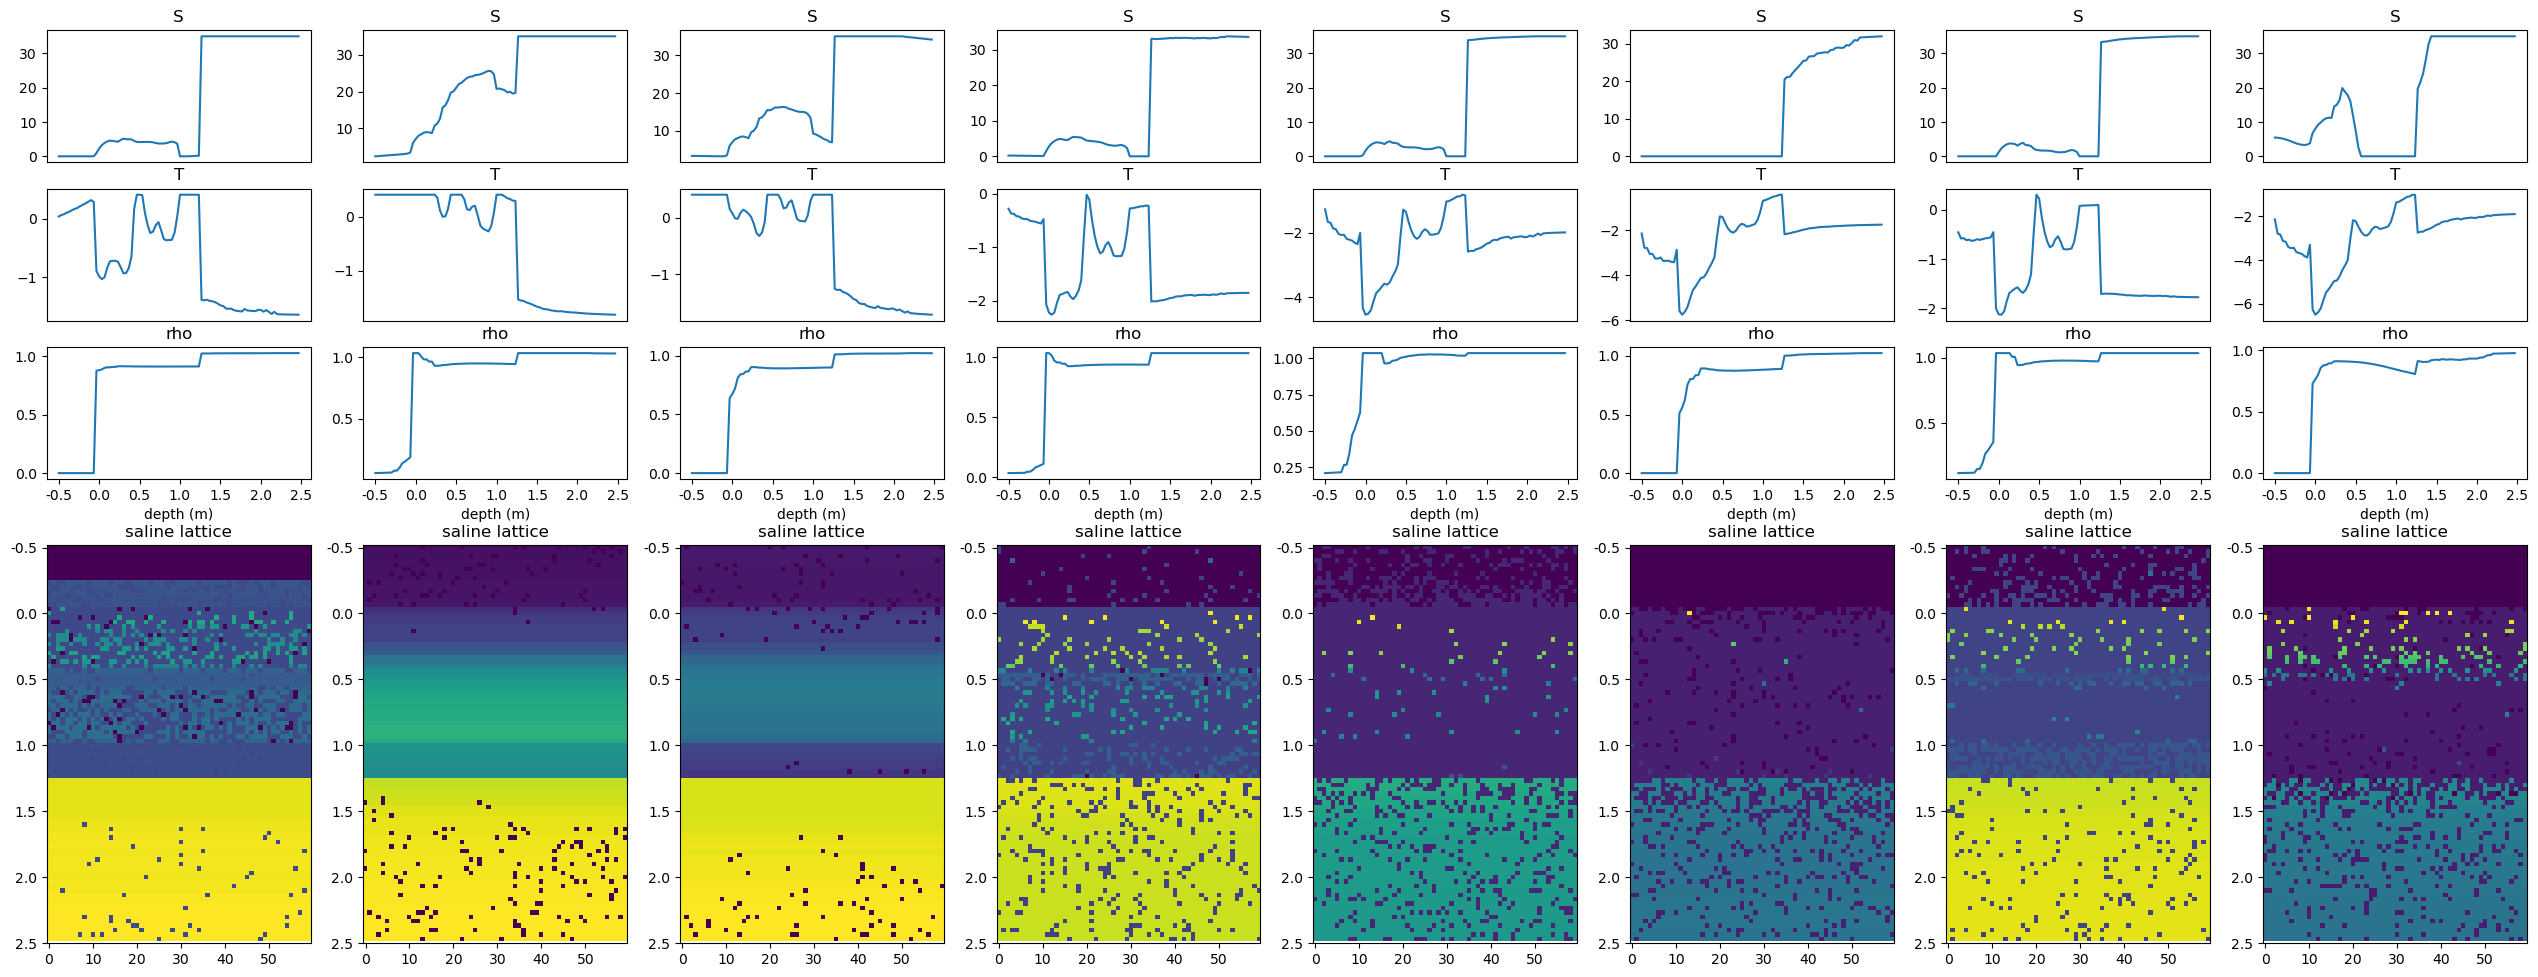

In [84]:
import script_CoreExplorer; importlib.reload(script_CoreExplorer)
import util_collector; importlib.reload(util_collector)

fn = 'em_resice.hdf5'
feed, floqs, vl, data_shapes = script_CoreExplorer.get_core(fn, 5000);
incidence_n = len(floqs); print(floqs)

def augment_func(T, S, rho, nums=100, L=(5, 90)):
    for v in (T, S, rho):
        vmin, vmax, vvar = v.amin(), v.amax(), v.var(dim=0)
        v = v[:,None].expand(-1,nums,-1).clone()
        for i in range(nums):
            vL = L[0] + ((L[1] - L[0]) * torch.rand(1)).to(v.device)
            v[:,i] = script_CoreExplorer.WienerNoiser(v[:,None,i], vvar, vL).clamp(vmin, vmax)[:,0]
        yield v.reshape(-1,v.shape[-1]) # collapse channel dim into batch dimension

preview_feed = feed#dwhitenr(feed)
S_, T_, rho_ = preview_feed[:,0,:vl[0]], preview_feed[:,0,vl[0]:vl[0]+vl[1]], preview_feed[:,0,vl[0]+vl[1]:vl[0]+vl[1]+vl[2]]

ci = 30
T, S, rho = T_[ci].clone(), S_[ci].clone(), rho_[ci].clone()
plt.figure(figsize=(9, 6))
bing = icesim.gen_lattice(T[None,],S[None,],rho[None,],(60,1)).cpu()[0,0,1:-1,1,1:-1].T;  bing[bing < 0] = -10
plt.subplot(3,2,1); plt.plot(S.cpu()); plt.title('S'); plt.xticks([])
plt.subplot(3,2,3); plt.plot(T.cpu()); plt.title('T'); plt.xticks([])
plt.subplot(3,2,5); plt.plot(rho.cpu()); plt.title('rho'); plt.xticks(np.linspace(0,90,7), np.linspace(-0.5,2.5,7).astype(str))
plt.subplot(1,2,2); plt.imshow(bing); plt.title('saline lattice'); plt.yticks(np.linspace(0,90,7), np.linspace(-0.5,2.5,7).astype(str))
plt.show()


num = 8
aug = torch.stack([el for el in augment_func(T_, S_, rho_, nums=num)], dim=0)[:,ci*num:(ci+1)*num]
T_, S_, rho_ = aug

l_ = T_.shape[0]
plt.figure(figsize=(4*l_, 12))
for i in range(l_):
    T, S, rho = T_[i], S_[i], rho_[i]
    
    bing = icesim.gen_lattice(T[None,],S[None,],rho[None,],(60,1)).cpu()[0,0,1:-1,1,1:-1].T;  bing[bing < 0] = -10
    plt.subplot(6,l_,1+i); plt.plot(S.cpu()); plt.title('S'); plt.xticks([])
    plt.subplot(6,l_,1+i+l_); plt.plot(T.cpu()); plt.title('T'); plt.xticks([])
    plt.subplot(6,l_,1+i+2*l_); plt.plot(rho.cpu()); plt.title('rho')
    plt.xticks(np.linspace(0,90,7), np.linspace(-0.5,2.5,7).astype(str)); plt.xlabel('depth (m)')
    plt.subplot(2,l_,l_+i+1); plt.imshow(bing); plt.title('saline lattice'); plt.yticks(np.linspace(0,90,7), np.linspace(-0.5,2.5,7).astype(str))
    
plt.show()